# Preprocessing

In [ ]:
import pandas as pd
df = pd.read_csv('/content/NHANES_20212023_merged_filtered 1.csv')

FileNotFoundError: [Errno 2] No such file or directory: '/content/NHANES_20212023_merged_filtered 1.csv'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# Aantal samples en features opvragen
samples, features = df.shape
print(f"Aantal samples (rijen): {samples}")
print(f"Aantal features (kolommen): {features}\n")

# Overzicht van datatypes (hoeveel van elk type)
print("Overzicht van datatypes:")
print(df.dtypes.value_counts())

# Toon de datatypes per kolom (eerste 30 kolommen als voorbeeld wegens de grote hoeveelheid)
print("\nDatatypes per kolom (eerste 30 kolommen):")
display(df.dtypes.head(30))

Aantal samples (rijen): 11933
Aantal features (kolommen): 486

Overzicht van datatypes:
float64    475
int64       10
object       1
Name: count, dtype: int64

Datatypes per kolom (eerste 30 kolommen):


,0
SEQN,int64
SDDSRVYR,int64
RIDSTATR,int64
RIAGENDR,int64
RIDAGEYR,int64
RIDAGEMN,float64
RIDRETH1,int64
RIDRETH3,int64
RIDEXMON,float64
RIDEXAGM,float64


In [ ]:
# Bereken het aantal en percentage ontbrekende waarden per kolom
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

# Combineer in een overzichtelijke tabel
missing_info = pd.DataFrame({
    'Aantal Ontbrekend': missing_count,
    'Percentage (%)': missing_percent
}).sort_values(by='Percentage (%)', ascending=False)

# Toon de top 20 kolommen met de meeste ontbrekende waarden
print("Top 20 kolommen met de meeste ontbrekende waarden:")
display(missing_info.head(20))

# Toon hoeveel kolommen helemaal geen ontbrekende waarden hebben
volledige_kolommen = (missing_count == 0).sum()
print(f"\nAantal kolommen zonder ontbrekende waarden: {volledige_kolommen} van de {df.shape[1]}")

Top 20 kolommen met de meeste ontbrekende waarden:


,Aantal Ontbrekend,Percentage (%)
BMIHEAD,11933,100.000000
DBQ073D,11917,99.865918
LBXHCG,11915,99.849158
BMIRECUM,11915,99.849158
DBQ073E,11912,99.824017
PHAALCMN,11908,99.790497
PHAALCHR,11908,99.790497
PHACOFMN,11904,99.756976
PHACOFHR,11904,99.756976
DBQ073C,11867,99.446912



Aantal kolommen zonder ontbrekende waarden: 12 van de 486


### Waarom kunnen er waarden ontbreken in de NHANES dataset?

1. **Doelgroepspecifieke vragen (Skip patterns):** Veel vragen in NHANES worden alleen gesteld aan specifieke demografische groepen (bijv. zwangerschapsvragen alleen aan vrouwen, of vragen over werk/alcohol/seksueel gedrag alleen aan volwassenen). Voor overige deelnemers is deze waarde `NaN` (Not a Number).
2. **Niet-deelname aan vervolgonderzoeken:** NHANES bestaat uit een interview thuis én een medisch onderzoek in een mobiel centrum (MEC). Sommige mensen doen wel mee aan het interview, maar komen niet opdagen voor het fysieke laboratoriumonderzoek.
3. **Weigering of 'Weet ik niet':** Deelnemers kunnen weigeren antwoord te geven op gevoelige vragen of het antwoord simpelweg niet weten.

### Hoe kunnen we dit aanpakken (Handling missingness)?

Het hangt af van de analyse die je wilt uitvoeren:
- **Verwijderen van kolommen:** Kolommen met extreem veel ontbrekende waarden (bijv. > 80%) kunnen vaak worden weggelaten als ze niet cruciaal zijn voor je onderzoek.
- **Imputatie (Imputation):** Ontbrekende waarden invullen met bijvoorbeeld het gemiddelde, de mediaan (voor numerieke data) of de modus (voor categorieën). Voor complexere analyses kan multipele imputatie (MICE) gebruikt worden.
- **Verwijderen van rijen (Listwise deletion):** Alleen rijen gebruiken die volledig zijn ingevuld voor de geselecteerde variabelen van je onderzoek. Let hierbij wel op dat dit kan leiden tot selectieve uitval (bias) als de data niet willekeurig mist.

In [ ]:
# Oorspronkelijke dimensies opslaan
oorspronkelijke_rijen, oorspronkelijke_kolommen = df.shape

# 1. Verwijder kolommen met meer dan 50% ontbrekende waarden
drempel_kolommen = len(df) * 0.5
df_clean = df.dropna(thresh=drempel_kolommen, axis=1)

# 2. Verwijder rijen met meer dan 50% ontbrekende waarden (van de overgebleven kolommen)
drempel_rijen = df_clean.shape[1] * 0.5
df_clean = df_clean.dropna(thresh=drempel_rijen, axis=0)

# Nieuwe dimensies
nieuwe_rijen, nieuwe_kolommen = df_clean.shape

print(f"Oorspronkelijke vorm: {oorspronkelijke_rijen} rijen, {oorspronkelijke_kolommen} kolommen")
print(f"Nieuwe vorm: {nieuwe_rijen} rijen, {nieuwe_kolommen} kolommen")
print(f"Verwijderde kolommen: {oorspronkelijke_kolommen - nieuwe_kolommen}")
print(f"Verwijderde rijen: {oorspronkelijke_rijen - nieuwe_rijen}")

# Update het hoofd-dataframe
df = df_clean

Oorspronkelijke vorm: 11933 rijen, 486 kolommen
Nieuwe vorm: 7354 rijen, 295 kolommen
Verwijderde kolommen: 191
Verwijderde rijen: 4579


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Selecteer alleen de numerieke kolommen voor statistische analyse
numeric_cols = df.select_dtypes(include=[np.number]).columns

# 1. Identificeer features met extreem lage variantie (bijna constante waarden)
variances = df[numeric_cols].var()
low_variance_cols = variances[variances < 0.01].index.tolist()

print(f"Aantal kolommen met extreem lage variantie (< 0.01): {len(low_variance_cols)}")
if low_variance_cols:
    print("Voorbeelden van lage variantie kolommen:", low_variance_cols[:10])

# 2. Bereken de Z-scores van fysiologische kernwaarden om biologische uitschieters te vinden
# Laten we kijken naar bekende variabelen zoals Gewicht (BMXWT) of Bloeddruk als deze aanwezig zijn
physiological_candidates = [col for col in df.columns if any(x in col.upper() for x in ['BMXWT', 'BMXHT', 'BMXBMI', 'BPXOSY', 'BPXODI'])]

print("\nBeschikbare fysiologische kernvariabelen:", physiological_candidates)

# Toon statistieken van deze kernvariabelen om uitschieters (outliers) te spotten
if physiological_candidates:
    display(df[physiological_candidates].describe())
else:
    # Als de specifieke kolommen niet direct herkenbaar zijn, tonen we algemene uitschieters op basis van variantie
    top_var_cols = variances.sort_values(ascending=False).index[:5]
    print("\nTop kolommen met de hoogste variantie:")
    display(df[top_var_cols].describe())

Aantal kolommen met extreem lage variantie (< 0.01): 61
Voorbeelden van lage variantie kolommen: ['SDDSRVYR', 'RIDSTATR', 'URDUCRLC', 'LBDBALC', 'LBDCHLC', 'LBDBANO', 'PHQ020', 'PHQ030', 'LBXPAN', 'LBDPANLC']

Beschikbare fysiologische kernvariabelen: ['BPXOSY1', 'BPXODI1', 'BPXOSY2', 'BPXODI2', 'BPXOSY3', 'BPXODI3', 'BMXWT', 'BMXHT', 'BMXBMI']


,BPXOSY1,BPXODI1,BPXOSY2,BPXODI2,BPXOSY3,BPXODI3,BMXWT,BMXHT,BMXBMI
count,6855.000000,6855.000000,6847.000000,6847.000000,6825.000000,6825.000000,7277.000000,7286.000000,7263.000000
mean,119.742524,73.105325,119.559369,72.475245,119.402784,72.160879,76.720540,163.487551,28.125348
std,18.491098,11.819723,18.462679,11.783280,18.358173,11.666460,25.854187,14.695468,7.781535
min,61.000000,33.000000,65.000000,32.000000,58.000000,26.000000,14.000000,93.100000,11.100000
25%,107.000000,65.000000,107.000000,65.000000,107.000000,64.000000,60.900000,157.000000,22.900000
50%,117.000000,72.000000,117.000000,72.000000,117.000000,72.000000,75.200000,164.800000,27.100000
75%,130.000000,80.000000,130.000000,80.000000,129.000000,79.000000,91.500000,172.900000,32.300000
max,232.000000,142.000000,233.000000,139.000000,232.000000,136.000000,248.200000,200.700000,74.800000


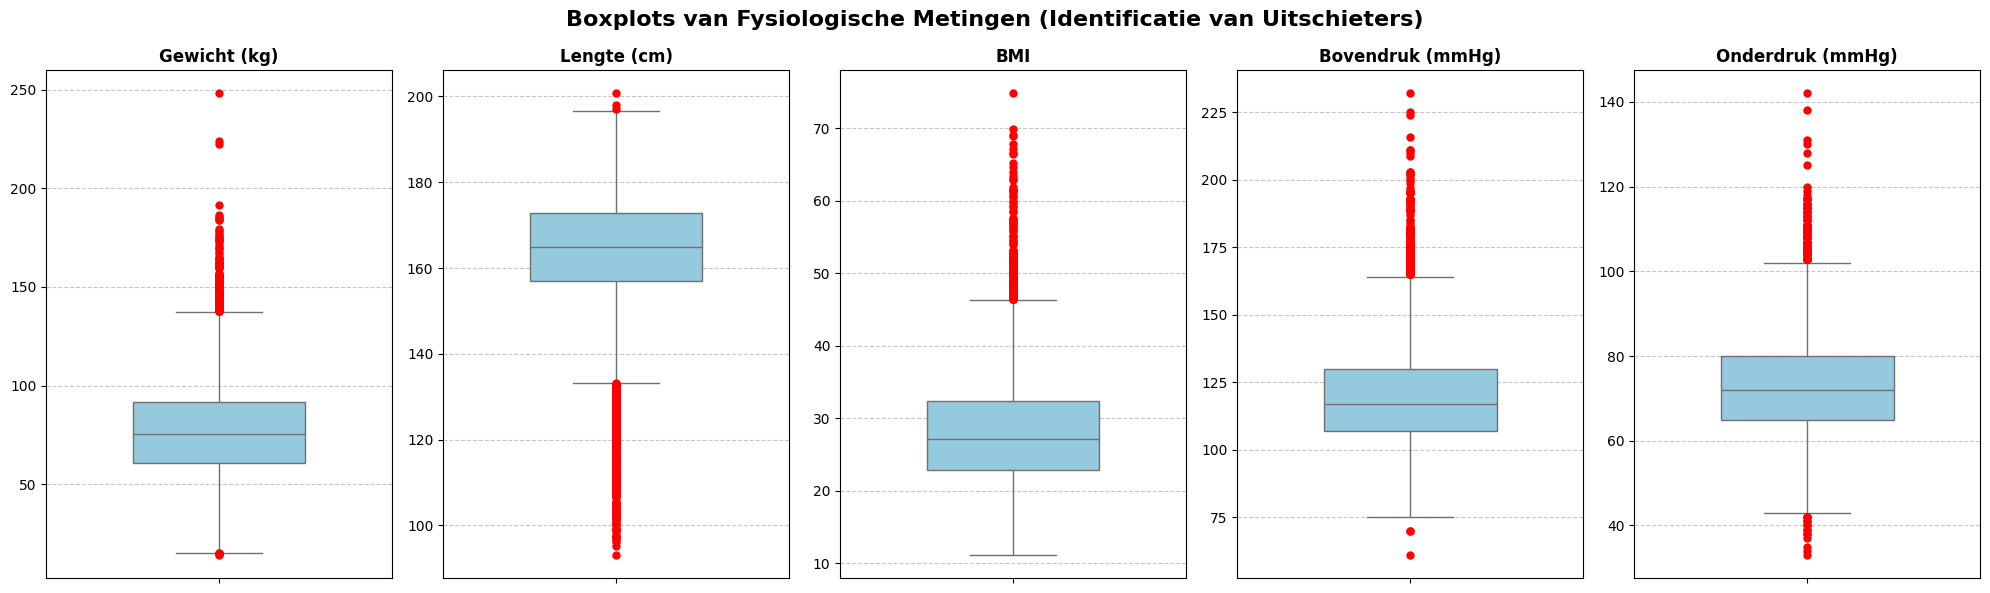

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# We selecteren een aantal interessante fysiologische variabelen voor de visualisatie
plot_cols = ['BMXWT', 'BMXHT', 'BMXBMI', 'BPXOSY1', 'BPXODI1']
column_labels = ['Gewicht (kg)', 'Lengte (cm)', 'BMI', 'Bovendruk (mmHg)', 'Onderdruk (mmHg)']

# Maak een figuur met meerdere subplots naast elkaar
fig, axes = plt.subplots(1, 5, figsize=(20, 6))
fig.suptitle('Boxplots van Fysiologische Metingen (Identificatie van Uitschieters)', fontsize=16, fontweight='bold')

for i, col in enumerate(plot_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='skyblue', width=0.5,
                flierprops=dict(marker='o', markerfacecolor='red', markersize=5, linestyle='none', markeredgecolor='red'))
    axes[i].set_title(column_labels[i], fontsize=12, fontweight='bold')
    axes[i].set_ylabel('')
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# 1. Bekijk de scheefheid (skewness) van onze geselecteerde variabelen
skewness = df[plot_cols].skew()
print("Scheefheid (skewness) van de geselecteerde variabelen:")
print(skewness)
print("(Een waarde > 1 of < -1 duidt op een sterk scheve verdeling)\n")

# We maken een kopie van het dataframe voor preprocessing demonstratie
df_preprocessed = df.copy()

# 2. Imputatie van resterende ontbrekende waarden met de mediaan
# (We selecteren hier alleen de numerieke kolommen)
numeric_cols = df_preprocessed.select_dtypes(include=[np.number]).columns
imputer = SimpleImputer(strategy='median')
df_preprocessed[numeric_cols] = imputer.fit_transform(df_preprocessed[numeric_cols])

# 3. Log-transformatie toepassen op sterk scheve fysiologische variabelen (bijv. Gewicht en BMI)
# We voegen een kleine constante toe (1e-5) om log(0) te voorkomen, hoewel deze biologisch hier niet 0 zijn
df_preprocessed['BMXWT_log'] = np.log1p(df_preprocessed['BMXWT'])
df_preprocessed['BMXBMI_log'] = np.log1p(df_preprocessed['BMXBMI'])

# 4. Standaardisatie (Z-score scaling) op de fysiologische variabelen
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_preprocessed[plot_cols])

# Laten we de getransformeerde features in een DataFrame zetten om het resultaat te bekijken
df_scaled = pd.DataFrame(scaled_features, columns=[f"{col}_scaled" for col in plot_cols])

print("Statistieken na standaardisatie (gemiddelde moet ~0 zijn, standaarddeviatie ~1):")
display(df_scaled.describe().round(3))

# Toon dat er geen ontbrekende waarden meer zijn in de numerieke kolommen van het preprocessed dataframe
remaining_missing = df_preprocessed[numeric_cols].isnull().sum().sum()
print(f"\nAantal resterende ontbrekende waarden in numerieke kolommen na imputatie: {remaining_missing}")

Scheefheid (skewness) van de geselecteerde variabelen:
BMXWT      0.436178
BMXHT     -1.293672
BMXBMI     0.956006
BPXOSY1    0.975627
BPXODI1    0.520696
dtype: float64
(Een waarde > 1 of < -1 duidt op een sterk scheve verdeling)

Statistieken na standaardisatie (gemiddelde moet ~0 zijn, standaarddeviatie ~1):


/tmp/ipykernel_722/3979233636.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_preprocessed['BMXWT_log'] = np.log1p(df_preprocessed['BMXWT'])
/tmp/ipykernel_722/3979233636.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_preprocessed['BMXBMI_log'] = np.log1p(df_preprocessed['BMXBMI'])


,BMXWT_scaled,BMXHT_scaled,BMXBMI_scaled,BPXOSY1_scaled,BPXODI1_scaled
count,7354.000,7354.000,7354.000,7354.000,7354.000
mean,-0.000,-0.000,-0.000,0.000,0.000
std,1.000,1.000,1.000,1.000,1.000
min,-2.438,-4.813,-2.200,-3.278,-3.507
25%,-0.607,-0.438,-0.661,-0.647,-0.704
50%,-0.059,0.089,-0.131,-0.143,-0.090
75%,0.568,0.643,0.529,0.529,0.523
max,6.669,2.543,6.037,6.294,6.042



Aantal resterende ontbrekende waarden in numerieke kolommen na imputatie: 0


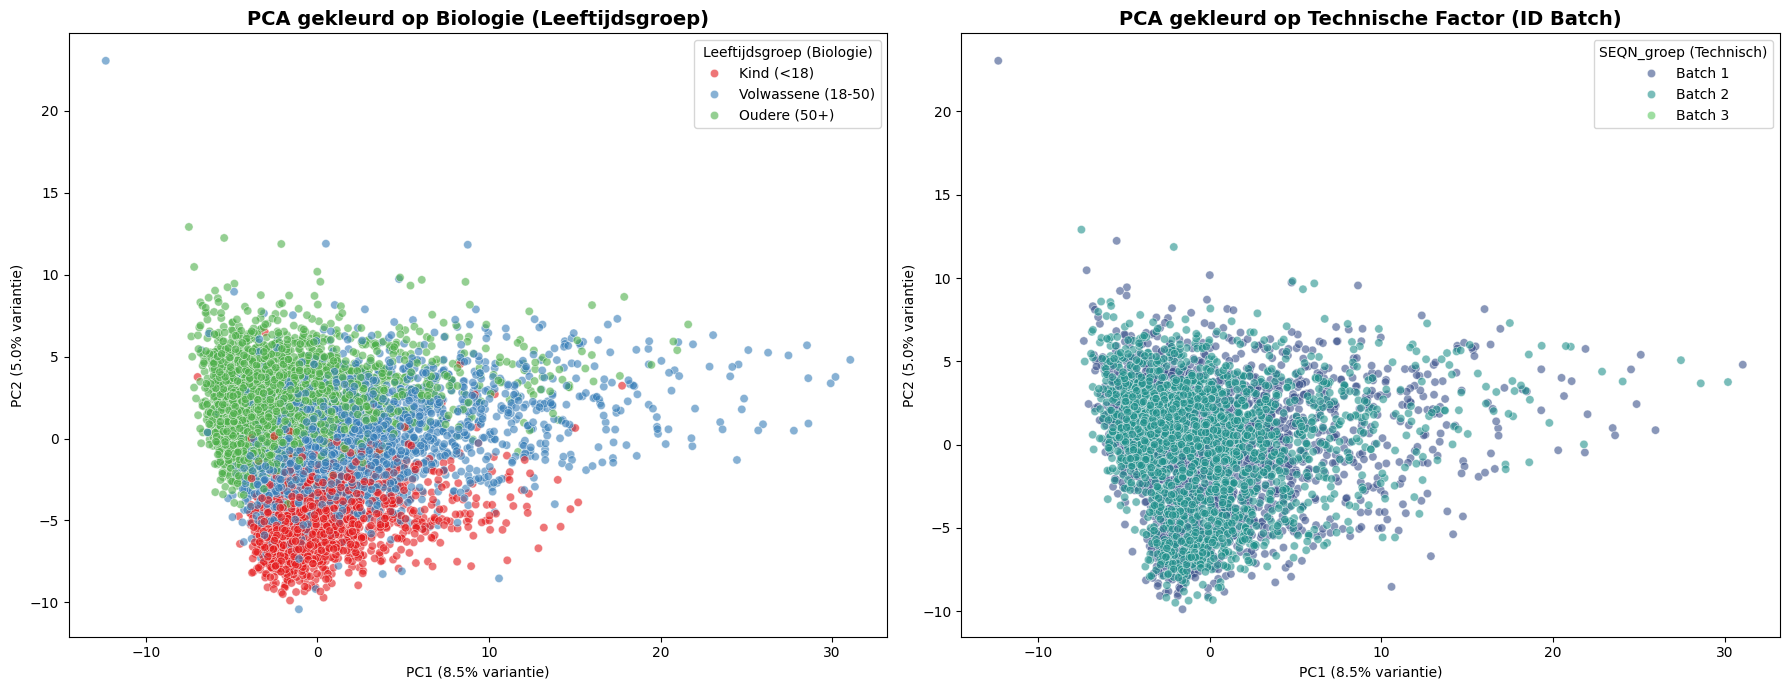

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# 1. We bereiden een bredere dataset voor de PCA voor met alle geïmputeerde numerieke kolommen
# We excluderen identificatie-variabelen zoals SEQN (sequentienummer) omdat dit een technische volgorde is
exclude_cols = ['SEQN', 'SDDSRVYR', 'RIDSTATR']
pca_features = [col for col in numeric_cols if col not in exclude_cols]

# Data schalen voor alle geselecteerde features
X = StandardScaler().fit_transform(df_preprocessed[pca_features])

# PCA uitvoeren
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# PCA resultaten toevoegen aan een tijdelijk DataFrame voor visualisatie
df_pca = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
df_pca['Geslacht (Biologie)'] = df_preprocessed['RIAGENDR'].values
# We maken een leeftijdscategorie aan als biologische factor
df_pca['Leeftijd'] = df_preprocessed['RIDAGEYR'].values
df_pca['Leeftijdsgroep (Biologie)'] = pd.cut(df_pca['Leeftijd'], bins=[0, 18, 50, 100], labels=['Kind (<18)', 'Volwassene (18-50)', 'Oudere (50+)'])
# We gebruiken SEQN (volgorde van opname/ID) als potentiële technische/batch factor
df_pca['SEQN_groep (Technisch)'] = pd.qcut(df_preprocessed['SEQN'], q=3, labels=['Batch 1', 'Batch 2', 'Batch 3'])

# 2. Visualisatie
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1: Biologische factor (Leeftijdsgroep)
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='Leeftijdsgroep (Biologie)', ax=axes[0], alpha=0.6, palette='Set1')
axes[0].set_title('PCA gekleurd op Biologie (Leeftijdsgroep)', fontsize=14, fontweight='bold')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variantie)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variantie)')

# Plot 2: Technische factor (SEQN / Deelnemersvolgorde als proxy voor meetvolgorde)
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='SEQN_groep (Technisch)', ax=axes[1], alpha=0.6, palette='viridis')
axes[1].set_title('PCA gekleurd op Technische Factor (ID Batch)', fontsize=14, fontweight='bold')
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variantie)')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variantie)')

plt.tight_layout()
plt.show()

### Onderzoeksvraag: BMI-kantelpunt voor Bloeddrukstijging
In dit deel bereiden we de specifieke variabelen voor die nodig zijn om te bepalen vanaf welke BMI de bloeddruk (systolisch en diastolisch) significant begint te stijgen, en of dit kantelpunt verschilt tussen mannen en vrouwen.

In [ ]:
# 1. Bereken de gemiddelde bloeddruk over de 3 opeenvolgende metingen voor een stabieler signaal
systolic_cols = ['BPXOSY1', 'BPXOSY2', 'BPXOSY3']
diastolic_cols = ['BPXODI1', 'BPXODI2', 'BPXODI3']

df_preprocessed['BPX_systolic_mean'] = df_preprocessed[systolic_cols].mean(axis=1)
df_preprocessed['BPX_diastolic_mean'] = df_preprocessed[diastolic_cols].mean(axis=1)

# 2. Maak het geslacht overzichtelijk (Labelen in plaats van 1.0 / 2.0)
# In NHANES: 1.0 = Male, 2.0 = Female
df_preprocessed['Geslacht_Label'] = df_preprocessed['RIAGENDR'].map({1.0: 'Man', 2.0: 'Vrouw'})

# 3. Maak een gerichte subset voor onze analyse om mee te werken
analysis_cols = [
    'SEQN',
    'RIDAGEYR',
    'Geslacht_Label',
    'BMXBMI',
    'BPX_systolic_mean',
    'BPX_diastolic_mean'
]

df_analysis = df_preprocessed[analysis_cols].copy()
print("Analyse dataframe succesvol aangemaakt!")
display(df_analysis.head())

# Controleer de basisstatistieken per geslacht
print("\nGemiddelde waarden per geslacht:")
display(df_analysis.groupby('Geslacht_Label')[['BMXBMI', 'BPX_systolic_mean', 'BPX_diastolic_mean']].mean())

Analyse dataframe succesvol aangemaakt!


/tmp/ipykernel_722/3585218081.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_preprocessed['BPX_systolic_mean'] = df_preprocessed[systolic_cols].mean(axis=1)
/tmp/ipykernel_722/3585218081.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_preprocessed['BPX_diastolic_mean'] = df_preprocessed[diastolic_cols].mean(axis=1)
/tmp/ipykernel_722/3585218081.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining a

,SEQN,RIDAGEYR,Geslacht_Label,BMXBMI,BPX_systolic_mean,BPX_diastolic_mean
0,130378.0,43.0,Man,27.0,132.666667,96.000000
1,130379.0,66.0,Man,33.5,117.000000,78.666667
2,130380.0,44.0,Vrouw,29.7,109.000000,78.333333
8,130386.0,34.0,Man,30.2,115.000000,73.666667
9,130387.0,68.0,Vrouw,42.6,141.333333,76.000000



Gemiddelde waarden per geslacht:


,BMXBMI,BPX_systolic_mean,BPX_diastolic_mean
Geslacht_Label,,,
Man,27.541230,121.470571,72.923198
Vrouw,28.598943,117.619012,72.215203


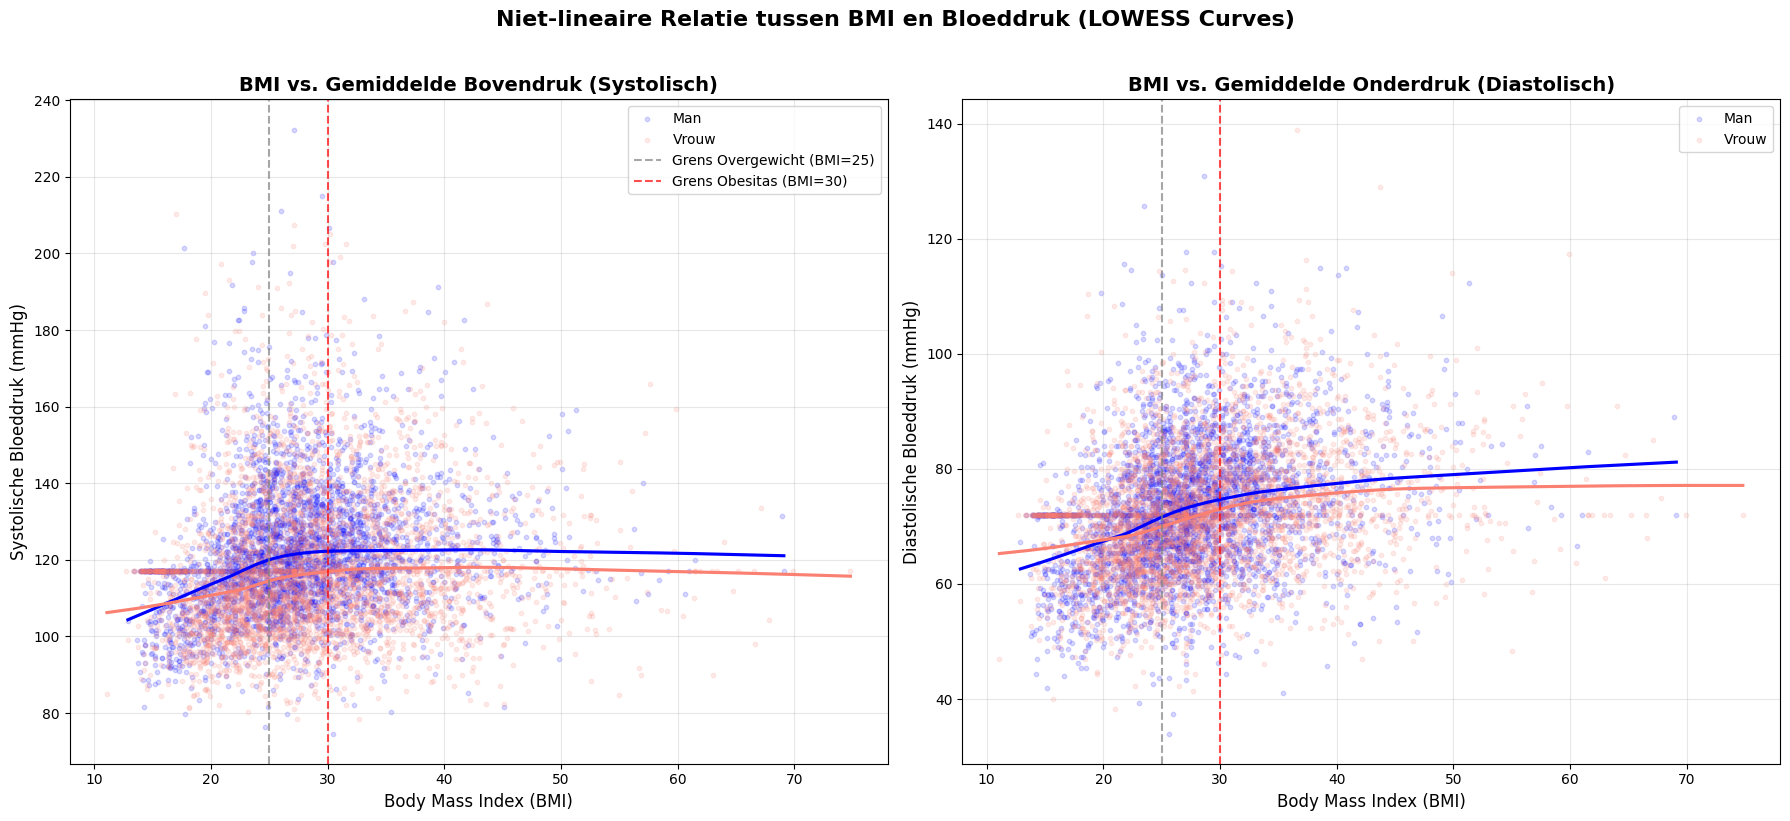

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# We maken een figuur met twee subplots: links voor systolisch (bovendruk), rechts voor diastolisch (onderdruk)
fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharex=True)

# 1. Systolische bloeddruk vs. BMI
sns.regplot(
    data=df_analysis[df_analysis['Geslacht_Label'] == 'Man'],
    x='BMXBMI', y='BPX_systolic_mean',
    ax=axes[0], label='Man', color='blue',
    scatter_kws={'alpha': 0.15, 's': 10},
    lowess=True
)
sns.regplot(
    data=df_analysis[df_analysis['Geslacht_Label'] == 'Vrouw'],
    x='BMXBMI', y='BPX_systolic_mean',
    ax=axes[0], label='Vrouw', color='salmon',
    scatter_kws={'alpha': 0.15, 's': 10},
    lowess=True
)
axes[0].set_title('BMI vs. Gemiddelde Bovendruk (Systolisch)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Body Mass Index (BMI)', fontsize=12)
axes[0].set_ylabel('Systolische Bloeddruk (mmHg)', fontsize=12)
axes[0].axvline(25, color='gray', linestyle='--', alpha=0.7, label='Grens Overgewicht (BMI=25)')
axes[0].axvline(30, color='red', linestyle='--', alpha=0.7, label='Grens Obesitas (BMI=30)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Diastolische bloeddruk vs. BMI
sns.regplot(
    data=df_analysis[df_analysis['Geslacht_Label'] == 'Man'],
    x='BMXBMI', y='BPX_diastolic_mean',
    ax=axes[1], label='Man', color='blue',
    scatter_kws={'alpha': 0.15, 's': 10},
    lowess=True
)
sns.regplot(
    data=df_analysis[df_analysis['Geslacht_Label'] == 'Vrouw'],
    x='BMXBMI', y='BPX_diastolic_mean',
    ax=axes[1], label='Vrouw', color='salmon',
    scatter_kws={'alpha': 0.15, 's': 10},
    lowess=True
)
axes[1].set_title('BMI vs. Gemiddelde Onderdruk (Diastolisch)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Body Mass Index (BMI)', fontsize=12)
axes[1].set_ylabel('Diastolische Bloeddruk (mmHg)', fontsize=12)
axes[1].axvline(25, color='gray', linestyle='--', alpha=0.7)
axes[1].axvline(30, color='red', linestyle='--', alpha=0.7)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Niet-lineaire Relatie tussen BMI en Bloeddruk (LOWESS Curves)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

Is de geporcessede data beschikbaar voor de andere types vragen?
Dit vormt een goede basis voor verkennende analyses en groepsvergelijkingen, maar voor echte AI-modellen trainen en multiple testing zijn er nog een paar cruciale vervolgstappen nodig. De technische rommel is verwijdert, er zijn geen lege kolommen meer. De categorische en de continue data zijn bovendien gescheiden zodat er geen rekenfouten meer ontstaan op labels zoals geslacht.
Maar voor AI datamodellen mogen we enkel de standaardisatie toepassen op de trainingsset en niet op de testset terwjil we dit n u op de volledige dataset hebben gedaan (om data leakage te voorkomen).  